# NBA Win Prediction

Dataset: https://www.kaggle.com/datasets/nathanlauga/nba-games


## Motivation, Problem Statement & PEAS

Predicting NBA game outcomes is a key problem in sports analytics with applications to strategies, media, and sportsbetting. Each game involves teams whose relative quality, scheduling fatigue, and recent performance all contribute to determining the winner. Uncertainty modeling is necessary because no deterministic method can model the randomness of NBA games; even a "heavily favored" team loses roughly 20–30% of the time. Win probability is thus more useful than classification because we are more interested in probabilities than labeling predictions. Observable features such as rest days and season win-percentage are noisy proxies for team strength, and a probabilistic model propagates that noise through to inference. Non-probabilistic approaches are limited, for example decision trees cut continuous features and cannot express a statement like "70% home win" Logistic regression similarly provides no explicit causal graph. These issues point us to a probabilistic approach.

### PEAS Framework

The *performance* measure is log loss, Brier score, accuracy and F1-score, with higher accuracy and F1 indicating better predictions (as in the last model) and higher log-likelihood indicating better  probability estimates. The *environment* is the set of NBA games from the past several years, which is partially observable because true team form is a latent variable that we can only approximate from prior results. The *actuator* is the probability the model outputs: P(HomeWin = 1 | evidence). The *sensors* are the observable pre-game features like home and away team overall win %, number of rest days since the team's last game, and the rolling 10-game win% variable we add on to the first model.


## Dataset & Preprocessing

The dataset comes from Kaggle, and is published by nathanlauga. games.csv contains 26,651 rows spanning the 2003-2022 seasons, including preseason, playoff and play-in games and 29 duplicated GAME_IDs. After de-duplicating and keeping only regular-season games (GAME_ID prefix 2) we have 23,244 games. Another file ranking.csv provides daily standings snapshots with team win percentages and provides data for form features.

The task is binary classification given only features observable prior to the game, no in-game statistics, to predict whether the home team wins or loses.

HomeWin is a binary target variable. HomeWinPct and AwayWinPct are continuous season win-percentage values that are discretized into the ordinal categories Weak, Average, and Strong. HomeRestDays and AwayRestDays are integer counts that are discretized into BackToBack, NormalRest, and WellRested. WinPctDiff is the difference between home and away win percentages, binned into AwayStronger, Even, and HomeStronger. RestDiff is the difference in rest days, binned into AwayRestAdv, EvenRest, and HomeRestAdv. HomeRoll10 and AwayRoll10 are new continuous features, binned into Cold, Average, and Hot.

### Preprocessing Steps

Season win percentage is joined to each game using pandas merge_asof in the backward direction with allow_exact_matches=False and matched on (team, season), so only standings published strictly before the game date are used. Standings dated the same day as a game already include that game's result, so allowing exact matches leaks the label. Rest days are computed by iterating over games sorted by date and showing the gap since each team's most recent appearance in the same season. The rolling win percentage is computed by building a flat per team game result log that combines home and away appearances in chronological order, then applying shift(1).rolling(10).mean() within each team-season. All continuous features are discretized using fixed thresholds based on domain knowledge. Rows containing NaN in the feature set is from mostly early games and are dropped since they make up a small portion of the data. The train/test split is temporal: seasons 2003-2018 are used for training and 2019-2022 for testing, so the model never sees games from the future.

### Justifications for design

Temporal ordering is enforced throughout so that no information from the future enters the model's inputs. The GAME_ID join for rolling statistics is a deliberate departure from the original merge_asof approach: because shift(1).rolling() is applied inside the sorted log before the join, the result for any given game reflects only that team's performance in JUST prior games. The discretization reduces sparsity in the CPTs and keeps the model interpretable.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
games = pd.read_csv("data/games.csv")
ranking = pd.read_csv("data/ranking.csv")

# games.csv has 29 duplicated GAME_IDs; every merge on GAME_ID below would multiply them
games = games.drop_duplicates('GAME_ID')
# GAME_ID / SEASON_ID prefix: 1 = preseason, 2 = regular season, 4 = playoffs, 5 = play-in
# Want to just predict regular season games (2)
games = games[games['GAME_ID'].astype(str).str[0] == '2'].copy()
ranking = ranking[ranking['SEASON_ID'].astype(str).str[0] == '2'].copy()
ranking['SEASON'] = ranking['SEASON_ID'] % 10000

print("Regular-season games:", len(games))
print("Home-win base rate: ", games['HOME_TEAM_WINS'].mean())

Regular-season games: 23244
Home-win base rate:  0.5881517811048013


In [3]:
# Preprocessing
games['GAME_DATE_EST'] = pd.to_datetime(games['GAME_DATE_EST'])
ranking['STANDINGSDATE'] = pd.to_datetime(ranking['STANDINGSDATE'])
games = games.sort_values(['GAME_DATE_EST', 'GAME_ID']).reset_index(drop=True)
ranking = ranking.sort_values('STANDINGSDATE').reset_index(drop=True)

def attach_win_pct(games_df, ranking_df, team_col, out_col):
    side = games_df[['GAME_ID', 'SEASON', team_col, 'GAME_DATE_EST']].copy().sort_values('GAME_DATE_EST')
    side = pd.merge_asof(
        side,
        ranking_df[['TEAM_ID', 'SEASON', 'STANDINGSDATE', 'W_PCT']],
        left_on='GAME_DATE_EST', right_on='STANDINGSDATE',
        left_by=[team_col, 'SEASON'], right_by=['TEAM_ID', 'SEASON'],
        direction='backward',
        allow_exact_matches=False  # same-day standings already include this game's result
    )
    return side.set_index('GAME_ID')['W_PCT'].rename(out_col)

games['HomeWinPct'] = games['GAME_ID'].map(attach_win_pct(games, ranking, 'HOME_TEAM_ID', 'HomeWinPct'))
games['AwayWinPct'] = games['GAME_ID'].map(attach_win_pct(games, ranking, 'VISITOR_TEAM_ID', 'AwayWinPct'))

last_game = {}
home_rest = []
away_rest = []
for _, row in games.iterrows():
    d, s, h, a = row['GAME_DATE_EST'], row['SEASON'], row['HOME_TEAM_ID'], row['VISITOR_TEAM_ID']
    home_rest.append((d - last_game[h, s]).days - 1 if (h, s) in last_game else 2)
    away_rest.append((d - last_game[a, s]).days - 1 if (a, s) in last_game else 2)
    last_game[h, s] = d
    last_game[a, s] = d

games['HomeRestDays'] = home_rest
games['AwayRestDays'] = away_rest
assert games['GAME_ID'].is_unique

In [4]:
# Rolling 10-game win % function
ROLL_WINDOW = 10

home_log = games[['GAME_DATE_EST', 'GAME_ID', 'SEASON', 'HOME_TEAM_ID', 'HOME_TEAM_WINS']].copy()
home_log.rename(columns={'HOME_TEAM_ID': 'team_id', 'HOME_TEAM_WINS': 'win'}, inplace=True)

away_log = games[['GAME_DATE_EST', 'GAME_ID', 'SEASON', 'VISITOR_TEAM_ID', 'HOME_TEAM_WINS']].copy()
away_log['win'] = 1 - away_log['HOME_TEAM_WINS']
away_log.rename(columns={'VISITOR_TEAM_ID': 'team_id'}, inplace=True)
away_log = away_log[['GAME_DATE_EST', 'GAME_ID', 'SEASON', 'team_id', 'win']]

team_log = (
    pd.concat(
        [home_log[['GAME_DATE_EST', 'GAME_ID', 'SEASON', 'team_id', 'win']], away_log],
        ignore_index=True
    )
    .sort_values(['team_id', 'GAME_DATE_EST', 'GAME_ID'])
    .reset_index(drop=True)
)

# shift(1) so a game's own result is never part of its feature
team_log['roll_wpct'] = (
    team_log
    .groupby(['team_id', 'SEASON'], group_keys=False)['win']
    .apply(lambda x: x.shift(1).rolling(ROLL_WINDOW, min_periods=3).mean())
)

roll = team_log.set_index(['GAME_ID', 'team_id'])['roll_wpct']
games['HomeRoll10'] = roll.reindex(pd.MultiIndex.from_arrays([games['GAME_ID'], games['HOME_TEAM_ID']])).values
games['AwayRoll10'] = roll.reindex(pd.MultiIndex.from_arrays([games['GAME_ID'], games['VISITOR_TEAM_ID']])).values
assert games['GAME_ID'].is_unique

n_nan_home = games['HomeRoll10'].isna().sum()
n_nan_away = games['AwayRoll10'].isna().sum()
print(f'HomeRoll10 NaNs (early-season games, will bin to Average): {n_nan_home}/{len(games)}')
print(f'AwayRoll10 NaNs: {n_nan_away}/{len(games)}')
print()
print(games[['GAME_DATE_EST','HOME_TEAM_ID','VISITOR_TEAM_ID','HomeRoll10','AwayRoll10']].iloc[50:55])

HomeRoll10 NaNs (early-season games, will bin to Average): 908/23244
AwayRoll10 NaNs: 889/23244

   GAME_DATE_EST  HOME_TEAM_ID  VISITOR_TEAM_ID  HomeRoll10  AwayRoll10
50    2003-11-04    1610612759       1610612748    0.500000        0.00
51    2003-11-05    1610612755       1610612740    0.500000        0.75
52    2003-11-05    1610612764       1610612742    0.333333        0.75
53    2003-11-05    1610612753       1610612741    0.250000        0.25
54    2003-11-05    1610612752       1610612749    0.333333        0.50


In [5]:
# Discretization
def bin_strength(p):
    if pd.isna(p): return np.nan
    if p <= 0.40:  return 'Weak'
    if p <= 0.60:  return 'Average'
    return 'Strong'

def bin_rest(days):
    if days == 0:  return 'BackToBack'
    if days <= 2:  return 'NormalRest'
    return 'WellRested'

def bin_roll(p):
    if pd.isna(p): return 'Average'
    if p <= 0.35:  return 'Cold'
    if p <= 0.65:  return 'Average'
    return 'Hot'

games['HomeStrength'] = games['HomeWinPct'].apply(bin_strength)
games['AwayStrength'] = games['AwayWinPct'].apply(bin_strength)
games['HomeRest_bin'] = games['HomeRestDays'].apply(bin_rest)
games['AwayRest_bin'] = games['AwayRestDays'].apply(bin_rest)
games['HomeRoll_bin'] = games['HomeRoll10'].apply(bin_roll)
games['AwayRoll_bin'] = games['AwayRoll10'].apply(bin_roll)
games['WinPctDiff'] = games['HomeWinPct'] - games['AwayWinPct']
games['WinPctDiff_bin'] = pd.cut(games['WinPctDiff'], bins=[-np.inf, -0.10, 0.10, np.inf], labels=['AwayStronger', 'Even', 'HomeStronger'])
games['RestDiff'] = games['HomeRestDays'] - games['AwayRestDays']
games['RestDiff_bin'] = pd.cut(games['RestDiff'], bins=[-np.inf, -1, 0, np.inf], labels=['AwayRestAdv', 'EvenRest', 'HomeRestAdv'])
games['HomeWin'] = games['HOME_TEAM_WINS'].astype(int)

print(games[['HomeStrength','AwayStrength','WinPctDiff_bin', 'HomeRest_bin','AwayRest_bin','RestDiff_bin','HomeRoll_bin','AwayRoll_bin','HomeWin']].head(3))

  HomeStrength AwayStrength WinPctDiff_bin HomeRest_bin AwayRest_bin  \
0          NaN          NaN            NaN   NormalRest   NormalRest   
1          NaN          NaN            NaN   NormalRest   NormalRest   
2          NaN          NaN            NaN   NormalRest   NormalRest   

  RestDiff_bin HomeRoll_bin AwayRoll_bin  HomeWin  
0     EvenRest      Average      Average        1  
1     EvenRest      Average      Average        1  
2     EvenRest      Average      Average        1  


## Model Choice & Methodology

### Model Selection

This project uses a Bayesian Network implemented with the pgmpy library, as in the previous model. A BN is well suited to this problem because it encodes a causal story with a DAG that follows intuition of domain knowledge (stronger teams beat weaker ones, rested teams have an edge, and recent form reflects short-term momentum). The graphical structure also supports partial evidence if rest data is unavailable for a particular game; variable elimination marginalises it and returns a valid posterior. The model naturally expresses uncertainty through CPTs.

### Model Improvements

The baseline model uses season-long win percentage and rest differential as its only predictors, estimated with MLE. The improved model adds two new nodes that represent each team's win rate over their most recent 10 games. These nodes connect directly to HomeWin in the DAG, giving the model an independent signal about short-term momentum that the season-long win percentage cannot capture. Both models use the same MLE CPT estimation procedure, the same Variable Elimination inference engine, and the same evidence columns at prediction time. The key structural change is that HomeWin in this model has 2 more parents, making its CPT wider.

### Model Structure

The DAG is shown in the diagram below. HomeStrength and AwayStrength each point to WinPctDiff_bin (because the difference between team qualities determines which direction the win-percentage gap falls) and both also point directly to HomeWin. HomeRest_bin and AwayRest_bin each point to RestDiff_bin, which in turn points to HomeWin. The two new nodes HomeRoll_bin and AwayRoll_bin each point directly to HomeWin. This structure was validated by chi-square conditional independence tests: in every case the p-value was well below 0.05, confirming that none of the parent-child edges in the graph should be removed. CPT's are estimated by MLE. Variable Elimination computes P(HomeWin | E) according to the joint distribution defined by the CPTs. The MAP prediction is obtained by choosing whichever value of HomeWin has the higher posterior probability, which corresponds to the threshold of 0.5.

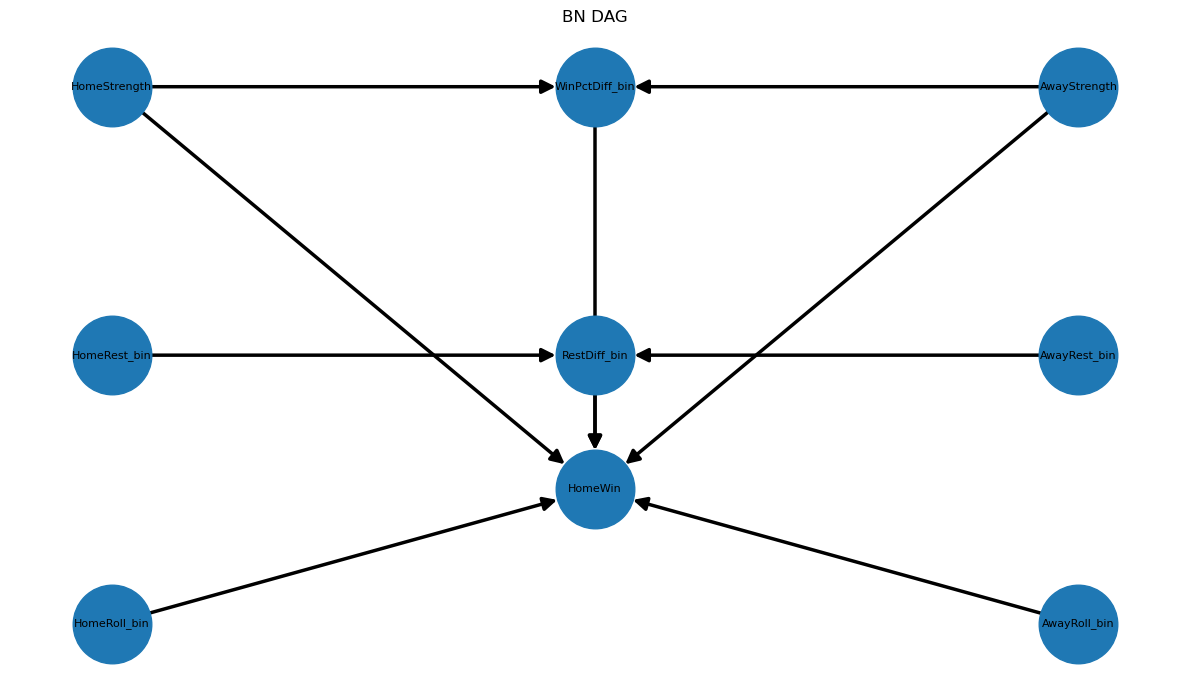

In [6]:
# DAG
edges = [
    ('HomeStrength', 'WinPctDiff_bin'),
    ('AwayStrength', 'WinPctDiff_bin'),
    ('HomeStrength', 'HomeWin'),
    ('AwayStrength', 'HomeWin'),
    ('HomeRest_bin', 'RestDiff_bin'),
    ('AwayRest_bin', 'RestDiff_bin'),
    ('WinPctDiff_bin', 'HomeWin'),
    ('RestDiff_bin', 'HomeWin'),
    ('HomeRoll_bin', 'HomeWin'),
    ('AwayRoll_bin', 'HomeWin'),
]
G = nx.DiGraph()
G.add_edges_from(edges)

pos = {
    'HomeStrength':  (-3,  2),
    'AwayStrength':  ( 3,  2),
    'WinPctDiff_bin':( 0,  2),
    'HomeRest_bin':  (-3,  0),
    'AwayRest_bin':  ( 3,  0),
    'RestDiff_bin':  ( 0,  0),
    'HomeRoll_bin':  (-3, -2),
    'AwayRoll_bin':  ( 3, -2),
    'HomeWin':  ( 0, -1),}

plt.figure(figsize=(12, 7))
nx.draw_networkx(G, pos, node_size=3200, font_size=8, arrowsize=20, width=2.5)
plt.title('BN DAG')
plt.axis('off')
plt.tight_layout()
plt.show()

## Training and Implementation

The feature matrix is built by discretizing the continuous inputs, then selecting the relevant column subset, which is split by season: 2003-2018 for training and 2019-2022 for testing. A random split would let the model learn from games played after the ones it is tested on. The compute_cpt helper function is applied to the training split to compute each CPT by grouping on parent columns and normalizing counts within each parent configuration. The network itself is fitted with pgmpy's BayesianEstimator using a BDeu prior (equivalent sample size 10), which smooths sparse parent configurations instead of producing the 0/1 probabilities that plain MLE gives for rarely seen combinations. Variable elimination is used both for example queries and for generating test-set predictions. The MAP decision threshold is 0.50. Because the goal is a probability, the main metrics are log loss and Brier score; accuracy is reported alongside them. The rolling window is ten games with a minimum of three to avoid extreme estimates at the very start of a season.

In [7]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

features = ['HomeWin', 'HomeStrength', 'AwayStrength', 'WinPctDiff_bin', 'HomeRest_bin', 'AwayRest_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin']

TEST_FROM_SEASON = 2019
df = games[features + ['SEASON']].dropna().copy().reset_index(drop=True)
df_train = df[df['SEASON'] < TEST_FROM_SEASON][features]
df_test = df[df['SEASON'] >= TEST_FROM_SEASON][features]

print(f'train: {df_train.shape}  test: {df_test.shape}')

train: (19349, 9)  test: (3838, 9)


In [8]:
# CPT helper (same pattern as original model)
def compute_cpt(df, child, parents):
    if not parents:
        counts = df[child].value_counts().sort_index().reset_index()
        counts.columns = [child, 'count']
        counts['P'] = counts['count'] / counts['count'].sum()
        return counts[[child, 'P']]

    counts = (
        df.groupby(parents + [child], observed=False)
        .size()
        .reset_index(name='count')
    )
    counts['P'] = counts.groupby(parents, observed=False)['count'].transform(
        lambda x: x / x.sum()
    )
    return counts[parents + [child, 'P']]


In [9]:
# Parameter Learning with improved CPTs
cpt_home_strength = compute_cpt(df_train, 'HomeStrength', [])
cpt_away_strength = compute_cpt(df_train, 'AwayStrength', [])
cpt_home_rest = compute_cpt(df_train, 'HomeRest_bin', [])
cpt_away_rest = compute_cpt(df_train, 'AwayRest_bin', [])
cpt_home_roll = compute_cpt(df_train, 'HomeRoll_bin', [])
cpt_away_roll = compute_cpt(df_train, 'AwayRoll_bin', [])
cpt_winpct_diff = compute_cpt(df_train, 'WinPctDiff_bin', ['HomeStrength', 'AwayStrength'])
cpt_rest_diff = compute_cpt(df_train, 'RestDiff_bin',   ['HomeRest_bin', 'AwayRest_bin'])
cpt_homewin = compute_cpt(df_train, 'HomeWin', ['WinPctDiff_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin'])

print('CPTs')
cpt_homewin.sort_values(['WinPctDiff_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin', 'HomeWin']).head(20)


CPTs


,WinPctDiff_bin,RestDiff_bin,HomeRoll_bin,AwayRoll_bin,HomeWin,P
0,AwayStronger,AwayRestAdv,Average,Average,0,0.618421
1,AwayStronger,AwayRestAdv,Average,Average,1,0.381579
2,AwayStronger,AwayRestAdv,Average,Cold,0,0.461538
3,AwayStronger,AwayRestAdv,Average,Cold,1,0.538462
4,AwayStronger,AwayRestAdv,Average,Hot,0,0.623016
5,AwayStronger,AwayRestAdv,Average,Hot,1,0.376984
6,AwayStronger,AwayRestAdv,Cold,Average,0,0.614786
7,AwayStronger,AwayRestAdv,Cold,Average,1,0.385214
8,AwayStronger,AwayRestAdv,Cold,Cold,0,0.563636
9,AwayStronger,AwayRestAdv,Cold,Cold,1,0.436364


In [10]:
## Inference
baseline_edges = [
    ('HomeStrength', 'WinPctDiff_bin'),
    ('AwayStrength', 'WinPctDiff_bin'),
    ('HomeStrength', 'HomeWin'),
    ('AwayStrength', 'HomeWin'),
    ('HomeRest_bin', 'RestDiff_bin'),
    ('AwayRest_bin', 'RestDiff_bin'),
    ('WinPctDiff_bin', 'HomeWin'),
    ('RestDiff_bin',   'HomeWin'),]
edges = baseline_edges + [
    ('HomeRoll_bin', 'HomeWin'),
    ('AwayRoll_bin', 'HomeWin'),]

def fit_bn(edges, data):
    m = DiscreteBayesianNetwork(edges)
    m.fit(data[list(m.nodes())], estimator=BayesianEstimator, prior_type='BDeu', equivalent_sample_size=10)
    return m

def predict_proba(m, data, ev_cols):
    # one VE query per distinct evidence combination, then map back onto the rows
    inf = VariableElimination(m)
    ev = data[ev_cols].astype(str)
    combos = ev.drop_duplicates()
    probs = {
        tuple(row): inf.query(['HomeWin'], evidence=dict(zip(ev_cols, row)), show_progress=False).get_value(HomeWin=1)
        for row in combos.itertuples(index=False)
    }
    return np.array([probs[tuple(row)] for row in ev.itertuples(index=False)])

model = fit_bn(edges, df_train)
infer = VariableElimination(model)

q_1 = infer.query(variables=['HomeWin'], evidence={'HomeStrength': 'Strong', 'AwayStrength': 'Weak', 'HomeRoll_bin': 'Hot', 'AwayRoll_bin': 'Cold'})
print('Query 1: P(HomeWin | Strong home hot streak vs Weak away cold streak)')
print(q_1, '\n')

q_2 = infer.query(variables=['HomeWin'], evidence={'WinPctDiff_bin': 'HomeStronger', 'RestDiff_bin': 'HomeRestAdv', 'HomeRoll_bin': 'Hot', 'AwayRoll_bin': 'Average'})
print('Query 2: P(HomeWin | HomeStronger + HomeRestAdv + Hot streak)')
print(q_2, '\n')

Ev_cols = ['HomeStrength', 'AwayStrength', 'WinPctDiff_bin', 'RestDiff_bin', 'HomeRoll_bin', 'AwayRoll_bin']
df_test_ = df_test.copy()
df_test_['P_HomeWin'] = predict_proba(model, df_test, Ev_cols)
df_test_['Predicted_HomeWin'] = (df_test_['P_HomeWin'] > 0.5).astype(int)
print(df_test_[['HomeWin', 'P_HomeWin', 'Predicted_HomeWin']].head(10))

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'HomeStrength': 'C', 'WinPctDiff_bin': 'O', 'AwayStrength': 'C', 'HomeWin': 'N', 'HomeRest_bin': 'C', 'RestDiff_bin': 'O', 'AwayRest_bin': 'C', 'HomeRoll_bin': 'C', 'AwayRoll_bin': 'C'}


Query 1: P(HomeWin | Strong home hot streak vs Weak away cold streak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.1360 |
+------------+----------------+
| HomeWin(1) |         0.8640 |
+------------+----------------+ 

Query 2: P(HomeWin | HomeStronger + HomeRestAdv + Hot streak)
+------------+----------------+
| HomeWin    |   phi(HomeWin) |
+============+================+
| HomeWin(0) |         0.2232 |
+------------+----------------+
| HomeWin(1) |         0.7768 |
+------------+----------------+ 

       HomeWin  P_HomeWin  Predicted_HomeWin
19349        1   0.592978                  1
19350        0   0.592978                  1
19351        1   0.592978                  1
19352        0   0.592978                  1
19353        1   0.592978                  1
19354        1   0.592978                  1
19355        1   0.592978                  1
19356        1   0.592978                  1
19357      

In [11]:
# Evaluation metrics
from sklearn.metrics import log_loss, brier_score_loss

baseline_model = fit_bn(baseline_edges, df_train)
baseline_ev = ['HomeStrength', 'AwayStrength', 'WinPctDiff_bin', 'RestDiff_bin']
y_true = df_test_['HomeWin'].values

def scores(p):
    y_hat = (p > 0.5).astype(int)
    return {
        'Log loss': log_loss(y_true, p),
        'Brier': brier_score_loss(y_true, p),
        'Accuracy': accuracy_score(y_true, y_hat),
        'Precision': precision_score(y_true, y_hat, zero_division=0),
        'Recall': recall_score(y_true, y_hat),
        'F1': f1_score(y_true, y_hat),
    }

results = pd.DataFrame({
    'Always home (base rate)': scores(np.full(len(y_true), df_train['HomeWin'].mean())),
    'v1 Baseline BN': scores(predict_proba(baseline_model, df_test, baseline_ev)),
    'v2 Improved BN (+Roll10)': scores(df_test_['P_HomeWin'].values),
}).T
print(f'Test seasons {TEST_FROM_SEASON}-{games["SEASON"].max()}, n = {len(y_true)} games')
results.round(4)

INFO:pgmpy: Datatype (N=numerical, C=Categorical Unordered, O=Categorical Ordered) inferred from data: 
 {'HomeStrength': 'C', 'WinPctDiff_bin': 'O', 'AwayStrength': 'C', 'HomeWin': 'N', 'HomeRest_bin': 'C', 'RestDiff_bin': 'O', 'AwayRest_bin': 'C'}


Test seasons 2019-2022, n = 3838 games


,Log loss,Brier,Accuracy,Precision,Recall,F1
Always home (base rate),0.6908,0.2488,0.5537,0.5537,1.0000,0.7127
v1 Baseline BN,0.6561,0.2314,0.6196,0.6280,0.7675,0.6908
v2 Improved BN (+Roll10),0.6674,0.2339,0.6167,0.6274,0.7576,0.6864


### Baseline metrics

The v1 baseline is now refit in this notebook on the same data and temporal split, so both models are evaluated on identical test games.

---

## Section 5 — Results and Conclusion

### 5.1 Quantitative Metrics


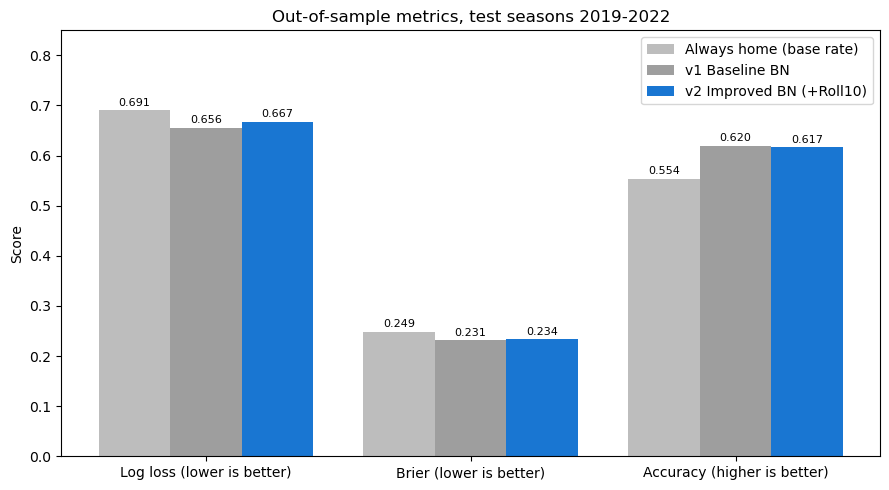

In [12]:
metrics_names = ['Log loss', 'Brier', 'Accuracy']
x, w = np.arange(len(metrics_names)), 0.27
colors = ['#bdbdbd', '#9e9e9e', '#1976d2']

fig, ax = plt.subplots(figsize=(9, 5))
for k, (name, row) in enumerate(results[metrics_names].iterrows()):
    bars = ax.bar(x + (k - 1) * w, row.values, w, label=name, color=colors[k])
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([m + (' (lower is better)' if m != 'Accuracy' else ' (higher is better)') for m in metrics_names])
ax.set_ylim(0, 0.85)
ax.set_ylabel('Score')
ax.set_title(f'Out-of-sample metrics, test seasons {TEST_FROM_SEASON}-{games["SEASON"].max()}')
ax.legend()
plt.tight_layout()
plt.savefig('comparison.png', dpi=120)
plt.show()

## Results and Conclusion

### Interpretation

When the matchup is asymmetric, for example when WinPctDiff_bin is HomeStronger or AwayStronger, the model correctly pushes the posterior far from 0.5 and achieves its highest classification accuracy. The rolling nodes add independent predictive signal in cases where season-long win percentage shows two teams as roughly equal. In other words, a team on a hot streak can now be distinguished from one in a cold stretch, and the model adjusts based on this. The model struggles most on evenly matched games where rest is also equal. In such cases the probability tends to be near the home-win base rate (58.8% over all regular-season games, 55.4% in the 2019-2022 test seasons), offering little additional information. Early-season games are a related weak spot: after one or two games a team's win percentage is 0 or 1, so opening-week matchups land in arbitrary bins. Injuries and roster changes are not captured by any of the features, which could affect prediction. Another shortfall is that 2 teams with win percentages like 0.61 and 0.59 are treated the same in the model because both fall in the 'average' bin. The Bayesian network also assumes conditional independence within each parent configuration, which is just an approximation.

### Model Comparison

The baseline model captures team quality and rest differential and assumes that season win percentage is a sufficient statistic for team strength. The improved model adds short term rolling form as an additional variable alongside the same season-wide data. Both models use the same BDeu-smoothed CPT estimation, the same inference engine, the same decision threshold and the same temporal test set. On the 2019-2022 test seasons both models clearly beat the always-home baseline (log loss about 0.656-0.667 vs 0.691, accuracy about 62% vs 55%), but the rolling-form nodes do not help: the improved model's log loss and Brier score are slightly worse than the baseline's. Adding two 3-state parents grows the HomeWin CPT from 81 to 729 parent configurations, many of them seen only a handful of times in training, so the extra short-term signal is outweighed by noisy, near-0/1 CPT entries for rare combinations. Rolling form also overlaps heavily with season win percentage, so it carries less independent information than expected.

### Implications

These results illustrate several core strengths of probabilistic graphical models for sports prediction. Calibrated probabilities are more actionable than point predictions because downstream decisions can be weighted by residual uncertainty rather than treated as certainties. The explicit DAG structure makes it transparent why the model assigns any particular probability — the posterior for a given game is a direct function of the team quality differential, rest advantage, and rolling form, all of which are interpretable to a domain expert. Partial evidence is also handled gracefully: if rest-day data is unavailable for a game, Variable Elimination marginalises it out and returns a valid posterior, whereas a discriminative model with a missing feature would either fail or require imputation. Hedging toward the base rate on even matchups is appropriate, since those games are genuinely uncertain, but calibration still needs to be checked directly with a reliability diagram rather than assumed.

### Weaknesses and Potential Extensions

The most significant weakness is the large 3-bin discretizations, which loses granularity and conflates teams that differ meaningfully in quality. A natural fix would be to use quantile-based or data-driven bins that better reflect the distribution of the data. Player features such as injury status, starter availability, or usage-weighted plus/minus would likely improve the model's ability to handle the case where a team's observed strength diverges from its actual strength on a given night. A dynamic Bayesian network or hidden Markov model could represent team strength as a latent state that evolves game-to-game rather than than with the fixed rolling window. Finally, replacing hard bin assignments with soft evidence and passing the raw win percentage as a distribution over strength bins would've reduced information loss at the discretization boundary.

### Conclusion

Evaluated on a temporal split, both Bayesian networks reach roughly 62% accuracy and a log loss near 0.66, well above the always-home baseline. The improved network, which adds rolling 10-game win percentage nodes as extra parents of HomeWin, does not beat the simpler baseline out of sample: the larger CPT overfits rare parent combinations. The main lessons are that strict temporal validation matters more than model complexity, and that new features need to be weighed against the parameters they add.